In [1]:

# ==========================================
# ONCOINSIGHT-AI
# Step 1: Load Breast Cancer Dataset
# ==========================================

# Import required libraries
import pandas as pd
import numpy as np

from sklearn.datasets import load_breast_cancer

# Load dataset
cancer = load_breast_cancer()

# Convert into a DataFrame
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

# Add target column
df["Diagnosis"] = cancer.target

# Display dataset information
print("Dataset successfully loaded!")
print("Dataset shape:", df.shape)

print("\nFirst five samples:")
display(df.head())

print("\nDiagnosis categories:")
print(cancer.target_names)

print("\nClass distribution:")
print(df["Diagnosis"].value_counts())


Dataset successfully loaded!
Dataset shape: (569, 31)

First five samples:


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Diagnosis categories:
['malignant' 'benign']

Class distribution:
Diagnosis
1    357
0    212
Name: count, dtype: int64


In [2]:

# ==========================================
# STEP 2: DATA QUALITY ASSESSMENT
# ==========================================

# 1. Check missing values
print("1. MISSING VALUES")
print("Total missing values:", df.isnull().sum().sum())

# 2. Check duplicate rows
print("\n2. DUPLICATE OBSERVATIONS")
print("Duplicate rows:", df.duplicated().sum())

# 3. Check data types
print("\n3. DATA TYPES")
print(df.dtypes.value_counts())

# 4. Statistical summary
print("\n4. STATISTICAL SUMMARY")
display(df.describe().round(2))

# 5. Diagnosis distribution
print("\n5. TARGET DISTRIBUTION")
print(df["Diagnosis"].value_counts())

print("\nPercentage distribution:")
print((df["Diagnosis"].value_counts(normalize=True) * 100).round(2))


1. MISSING VALUES
Total missing values: 0

2. DUPLICATE OBSERVATIONS
Duplicate rows: 0

3. DATA TYPES
float64    30
int64       1
Name: count, dtype: int64

4. STATISTICAL SUMMARY


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,Diagnosis
count,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,...,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00,569.00
mean,14.13,19.29,91.97,654.89,0.10,0.10,0.09,0.05,0.18,0.06,...,25.68,107.26,880.58,0.13,0.25,0.27,0.11,0.29,0.08,0.63
std,3.52,4.30,24.30,351.91,0.01,0.05,0.08,0.04,0.03,0.01,...,6.15,33.60,569.36,0.02,0.16,0.21,0.07,0.06,0.02,0.48
min,6.98,9.71,43.79,143.50,0.05,0.02,0.00,0.00,0.11,0.05,...,12.02,50.41,185.20,0.07,0.03,0.00,0.00,0.16,0.06,0.00
25%,11.70,16.17,75.17,420.30,0.09,0.06,0.03,0.02,0.16,0.06,...,21.08,84.11,515.30,0.12,0.15,0.11,0.06,0.25,0.07,0.00
50%,13.37,18.84,86.24,551.10,0.10,0.09,0.06,0.03,0.18,0.06,...,25.41,97.66,686.50,0.13,0.21,0.23,0.10,0.28,0.08,1.00
75%,15.78,21.80,104.10,782.70,0.11,0.13,0.13,0.07,0.20,0.07,...,29.72,125.40,1084.00,0.15,0.34,0.38,0.16,0.32,0.09,1.00
max,28.11,39.28,188.50,2501.00,0.16,0.35,0.43,0.20,0.30,0.10,...,49.54,251.20,4254.00,0.22,1.06,1.25,0.29,0.66,0.21,1.00



5. TARGET DISTRIBUTION
Diagnosis
1    357
0    212
Name: count, dtype: int64

Percentage distribution:
Diagnosis
1    62.74
0    37.26
Name: proportion, dtype: float64


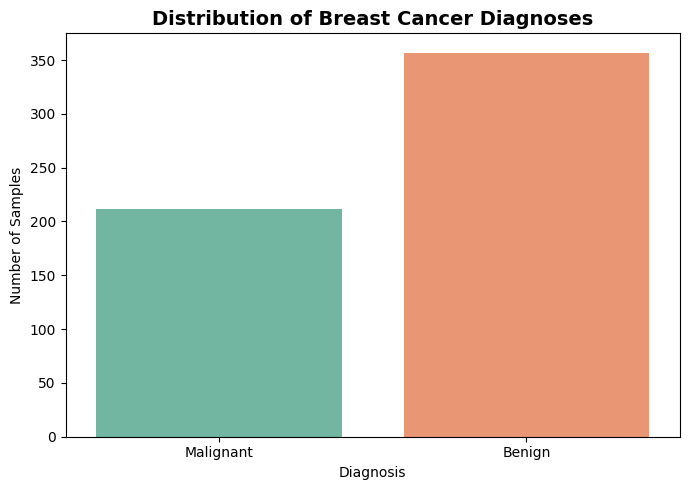

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

# Convert numerical diagnosis into readable labels
df["Diagnosis_Label"] = df["Diagnosis"].map({
    0: "Malignant",
    1: "Benign"
})

# Plot diagnosis distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Diagnosis_Label",
    hue="Diagnosis_Label",
    order=["Malignant", "Benign"],
    palette="Set2",
    legend=False
)

plt.title("Distribution of Breast Cancer Diagnoses",
          fontsize=14, fontweight="bold")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Samples")
plt.tight_layout()

plt.savefig("figures_diagnosis_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()


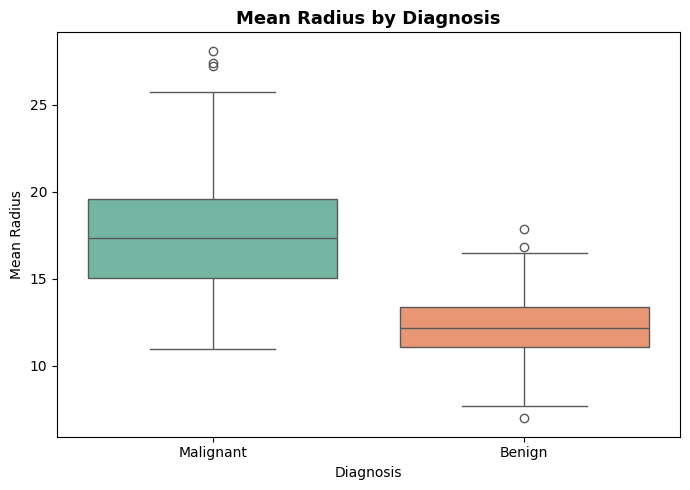

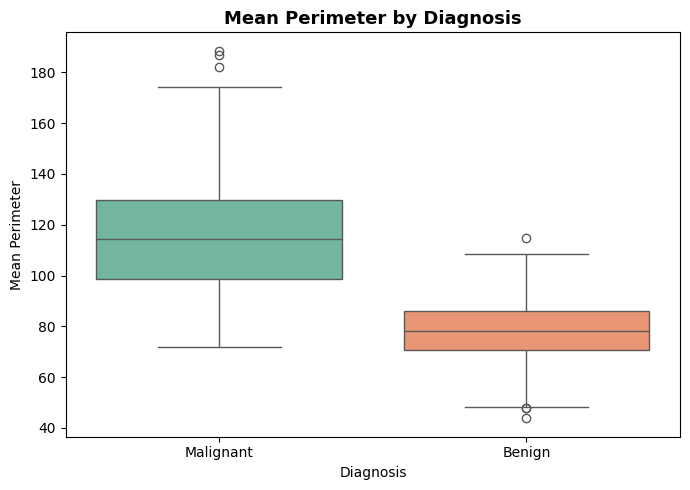

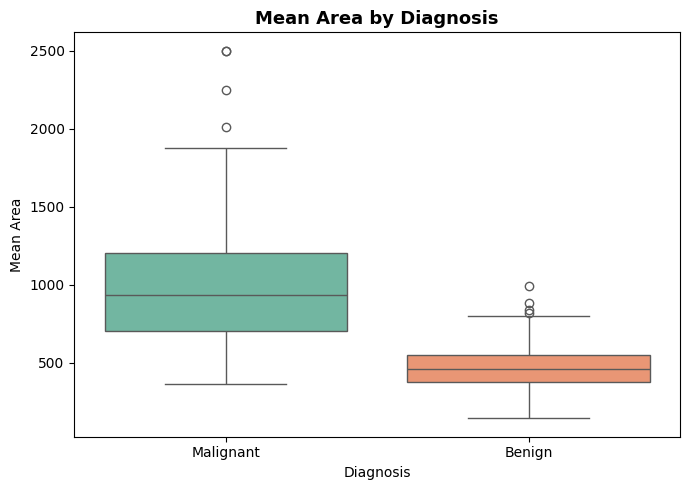

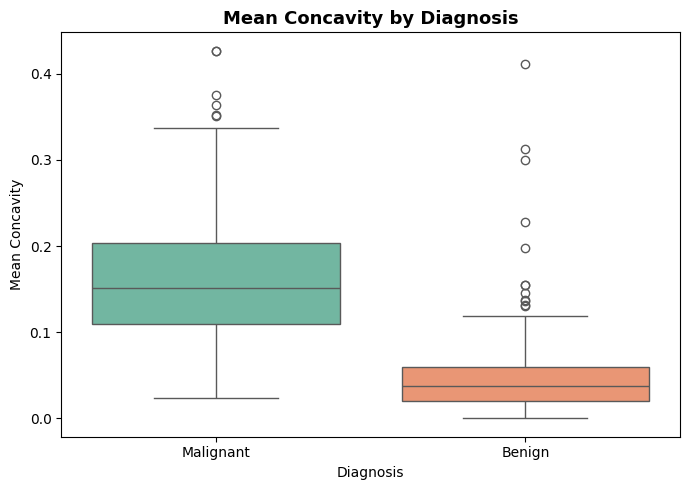

In [4]:

# Select four important features
selected_features = [
    "mean radius",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

# Create individual boxplots
for feature in selected_features:

    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x="Diagnosis_Label",
        y=feature,
        hue="Diagnosis_Label",
        order=["Malignant", "Benign"],
        palette="Set2",
        legend=False
    )

    plt.title(f"{feature.title()} by Diagnosis",
              fontsize=13, fontweight="bold")

    plt.xlabel("Diagnosis")
    plt.ylabel(feature.title())

    plt.tight_layout()
    plt.savefig(
        f"{feature.replace(' ', '_')}_comparison.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


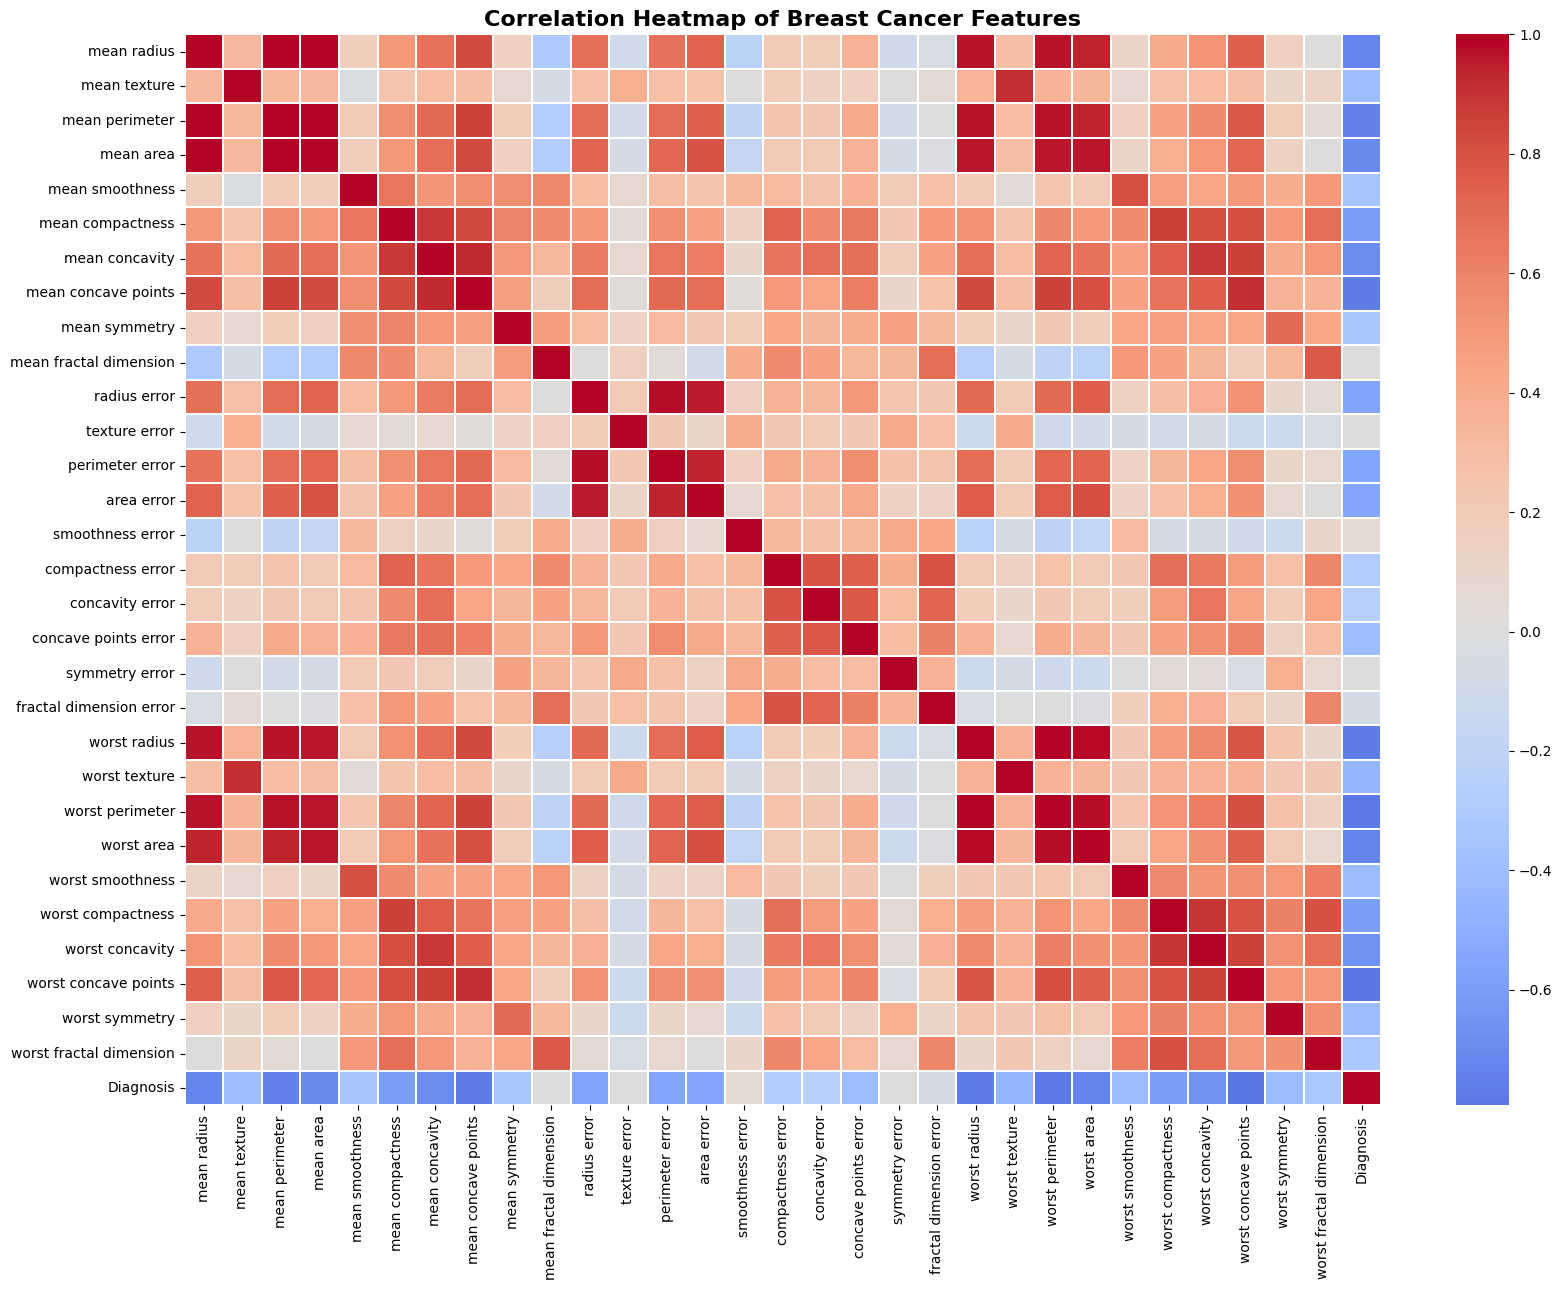

In [5]:

# Calculate correlation between numerical variables
correlation_matrix = df.drop(
    columns=["Diagnosis_Label"]
).corr()

# Plot correlation heatmap
plt.figure(figsize=(17, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.2,
    annot=False
)

plt.title("Correlation Heatmap of Breast Cancer Features",
          fontsize=16, fontweight="bold")

plt.tight_layout()

plt.savefig(
    "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [6]:

# Compare feature distributions numerically

features = [
    "mean radius",
    "mean perimeter",
    "mean area",
    "mean concavity"
]

for feature in features:

    print("\nFeature:", feature)

    summary = df.groupby("Diagnosis_Label")[feature].agg(
        ["mean", "median", "std", "min", "max"]
    )

    print(summary.round(3))



Feature: mean radius
                   mean  median    std     min    max
Diagnosis_Label                                      
Benign           12.147  12.200  1.781   6.981  17.85
Malignant        17.463  17.325  3.204  10.950  28.11

Feature: mean perimeter
                    mean  median     std    min    max
Diagnosis_Label                                       
Benign            78.075   78.18  11.807  43.79  114.6
Malignant        115.365  114.20  21.855  71.90  188.5

Feature: mean area
                    mean  median      std    min     max
Diagnosis_Label                                         
Benign           462.790   458.4  134.287  143.5   992.1
Malignant        978.376   932.0  367.938  361.6  2501.0

Feature: mean concavity
                  mean  median    std    min    max
Diagnosis_Label                                    
Benign           0.046   0.037  0.043  0.000  0.411
Malignant        0.161   0.151  0.075  0.024  0.427


In [7]:

# Correlation analysis

corr = df.drop(
    columns=["Diagnosis_Label"]
).corr()

# Extract unique feature pairs
upper = corr.where(
    np.triu(np.ones(corr.shape), k=1).astype(bool)
)

# Display top 15 highly correlated feature pairs
top_correlations = (
    upper.stack()
    .reset_index()
)

top_correlations.columns = [
    "Feature_1", "Feature_2", "Correlation"
]

top_correlations["Correlation"] = (
    top_correlations["Correlation"].round(3)
)

top_correlations = top_correlations.reindex(
    top_correlations["Correlation"].abs().sort_values(
        ascending=False
    ).index
)

print("Top 15 highly correlated feature pairs:")
display(top_correlations.head(15))


Top 15 highly correlated feature pairs:


,Feature_1,Feature_2,Correlation
1,mean radius,mean perimeter,0.998
411,worst radius,worst perimeter,0.994
59,mean perimeter,mean area,0.987
2,mean radius,mean area,0.987
412,worst radius,worst area,0.984
429,worst perimeter,worst area,0.978
256,radius error,perimeter error,0.973
78,mean perimeter,worst perimeter,0.970
19,mean radius,worst radius,0.970
76,mean perimeter,worst radius,0.969


In [8]:
from google.colab import files
import os
import zipfile

# Create figures directory
os.makedirs("OncoInsight_Figures", exist_ok=True)

# Save the heatmap
plt.figure(figsize=(17, 13))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Breast Cancer Feature Correlation")
plt.tight_layout()
plt.savefig(
    "OncoInsight_Figures/correlation_heatmap.png",
    dpi=300
)
plt.close()

In [9]:

# ==========================================
# STEP 4: TRAIN-TEST SPLITTING
# ==========================================

from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["Diagnosis", "Diagnosis_Label"])
y = df["Diagnosis"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training dataset:", X_train.shape)
print("Testing dataset:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training dataset: (455, 30)
Testing dataset: (114, 30)

Training class distribution:
Diagnosis
1    285
0    170
Name: count, dtype: int64

Testing class distribution:
Diagnosis
1    72
0    42
Name: count, dtype: int64


In [10]:

# ==========================================
# STEP 6: MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cancer.target_names
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "logistic_regression_confusion_matrix.png",
    dpi=300
)
plt.show()


NameError: name 'y_pred' is not defined

In [11]:

# ==========================================
# FIX: TRAIN MODEL AND GENERATE PREDICTIONS
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Create model
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=5000,
        random_state=42
    ))
])

# Train model
lr_model.fit(X_train, y_train)

# Generate predictions
y_pred = lr_model.predict(X_test)

# Generate prediction probabilities for malignant class
y_prob = lr_model.predict_proba(X_test)[:, 0]

print("Model trained successfully!")
print("Predictions generated:", len(y_pred))
print("Prediction probabilities generated:", len(y_prob))


Model trained successfully!
Predictions generated: 114
Prediction probabilities generated: 114


MODEL PERFORMANCE
-------------------------
Accuracy: 0.9825
ROC-AUC: 0.0046

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



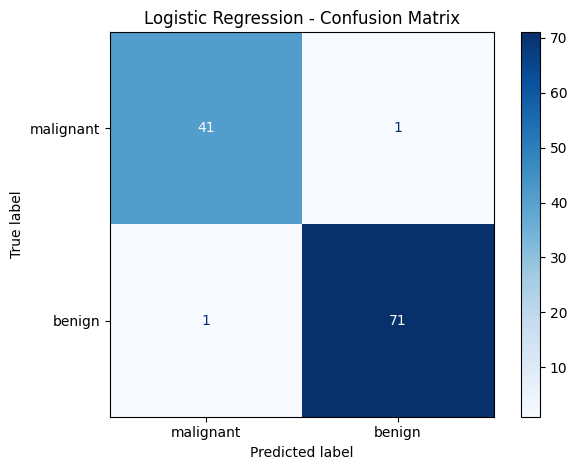

In [12]:

# ==========================================
# STEP 6: MODEL EVALUATION
# ==========================================

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("MODEL PERFORMANCE")
print("-------------------------")
print("Accuracy:", round(accuracy, 4))
print("ROC-AUC:", round(auc, 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=cancer.target_names
))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=cancer.target_names
)

disp.plot(cmap="Blues")
plt.title("Logistic Regression - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "logistic_regression_confusion_matrix.png",
    dpi=300
)
plt.show()


In [13]:

from sklearn.metrics import roc_auc_score

# Extract probability of benign class (class 1)
y_prob_benign = lr_model.predict_proba(X_test)[:, 1]

# Calculate ROC-AUC
correct_auc = roc_auc_score(
    y_test,
    y_prob_benign
)

print("Corrected ROC-AUC:",
      round(correct_auc, 4))


Corrected ROC-AUC: 0.9954


In [14]:

# Treat malignant (class 0) as the positive class
y_test_malignant = (y_test == 0).astype(int)

y_prob_malignant = lr_model.predict_proba(X_test)[:, 0]

malignant_auc = roc_auc_score(
    y_test_malignant,
    y_prob_malignant
)

print("Malignant ROC-AUC:", round(malignant_auc, 4))


Malignant ROC-AUC: 0.9954


In [15]:

# ==========================================
# STEP 7: RANDOM FOREST CLASSIFICATION
# ==========================================

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Initialize Random Forest
rf_model = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    random_state=42,
    class_weight="balanced"
)

# Train model
rf_model.fit(X_train, y_train)

# Generate predictions
rf_pred = rf_model.predict(X_test)

# Extract probabilities for benign (class 1)
benign_index = list(rf_model.classes_).index(1)

rf_prob = rf_model.predict_proba(X_test)[:, benign_index]

print("Random Forest trained successfully!")
print("Predictions generated:", len(rf_pred))


Random Forest trained successfully!
Predictions generated: 114


In [16]:

# ==========================================
# MODEL COMPARISON
# ==========================================

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        rf_accuracy
    ],
    "ROC_AUC": [
        correct_auc,
        rf_auc
    ]
})

display(model_comparison.round(4))


NameError: name 'rf_accuracy' is not defined

In [17]:
print("rf_model exists:", "rf_model" in globals())
print("rf_pred exists:", "rf_pred" in globals())
print("rf_prob exists:", "rf_prob" in globals())
print("rf_accuracy exists:", "rf_accuracy" in globals())

rf_model exists: True
rf_pred exists: True
rf_prob exists: True
rf_accuracy exists: False


In [18]:
from sklearn.metrics import accuracy_score, roc_auc_score

rf_accuracy = accuracy_score(y_test, rf_pred)
rf_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Accuracy:", round(rf_accuracy, 4))
print("Random Forest ROC-AUC:", round(rf_auc, 4))

Random Forest Accuracy: 0.9474
Random Forest ROC-AUC: 0.9937


In [19]:
model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [accuracy, rf_accuracy],
    "ROC_AUC": [correct_auc, rf_auc]
})

display(model_comparison.round(4))

,Model,Accuracy,ROC_AUC
0,Logistic Regression,0.9825,0.9954
1,Random Forest,0.9474,0.9937


TOP 15 IMPORTANT FEATURES


,Feature,Importance
22,worst perimeter,0.1451
23,worst area,0.1390
27,worst concave points,0.1097
7,mean concave points,0.0965
20,worst radius,0.0786
0,mean radius,0.0498
6,mean concavity,0.0498
26,worst concavity,0.0436
2,mean perimeter,0.0425
13,area error,0.0388


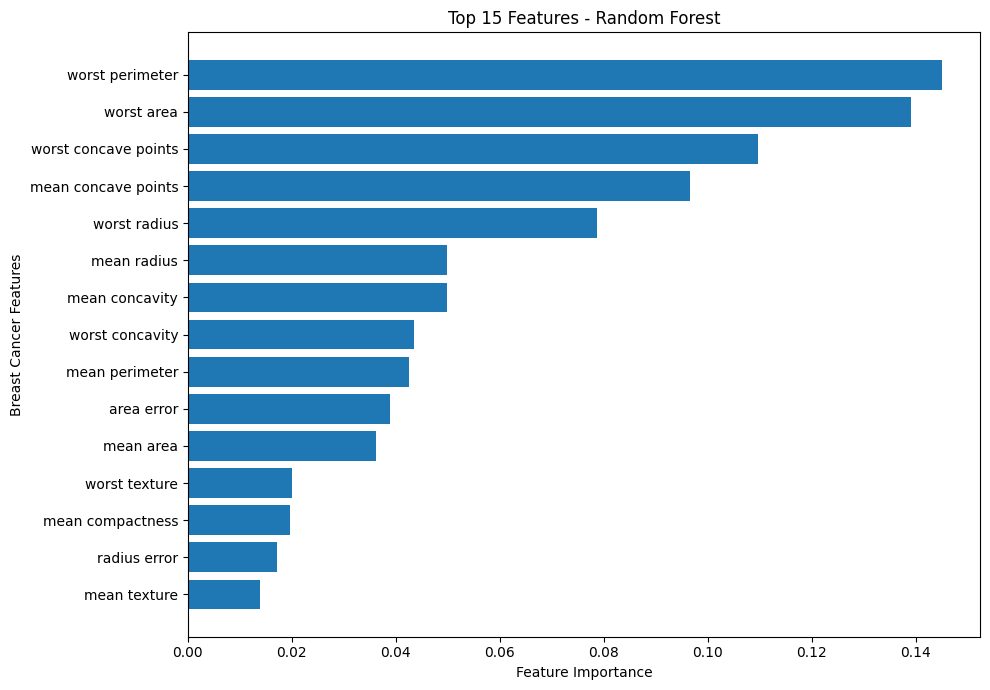

In [20]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort from highest to lowest
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features
print("TOP 15 IMPORTANT FEATURES")
display(feature_importance.head(15).round(4))

# Plot top 15 features
plt.figure(figsize=(10, 7))

top_features = feature_importance.head(15).sort_values(
    by="Importance"
)

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Breast Cancer Features")
plt.title("Top 15 Features - Random Forest")

plt.tight_layout()
plt.savefig("OncoInsight_Top15_Feature_Importance.png", dpi=300)
plt.show()

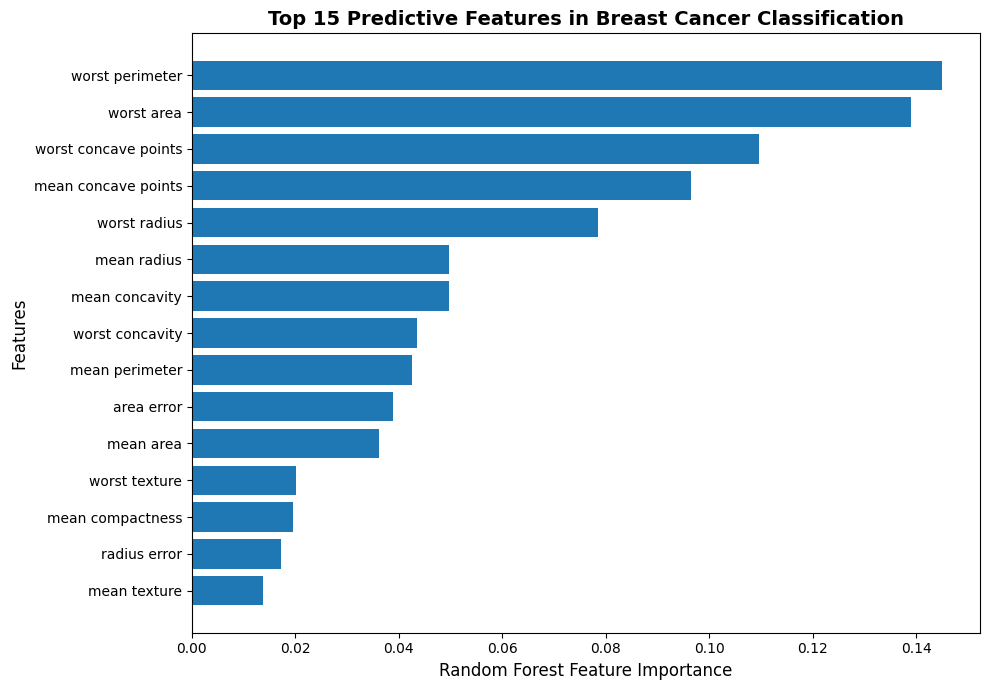

In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

top15 = feature_importance.head(15).sort_values(
    "Importance",
    ascending=True
)

plt.barh(
    top15["Feature"],
    top15["Importance"]
)

plt.xlabel("Random Forest Feature Importance", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.title(
    "Top 15 Predictive Features in Breast Cancer Classification",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "OncoInsight_Top15_Feature_Importance_Publication.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [22]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = ["accuracy", "roc_auc"]

lr_cv = cross_validate(
    lr_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

rf_cv = cross_validate(
    rf_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring
)

cv_results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Mean Accuracy": [
        lr_cv["test_accuracy"].mean(),
        rf_cv["test_accuracy"].mean()
    ],
    "Mean ROC-AUC": [
        lr_cv["test_roc_auc"].mean(),
        rf_cv["test_roc_auc"].mean()
    ],
    "Accuracy SD": [
        lr_cv["test_accuracy"].std(),
        rf_cv["test_accuracy"].std()
    ]
})

display(cv_results.round(4))

,Model,Mean Accuracy,Mean ROC-AUC,Accuracy SD
0,Logistic Regression,0.9780,0.9959,0.0098
1,Random Forest,0.9626,0.9923,0.0164


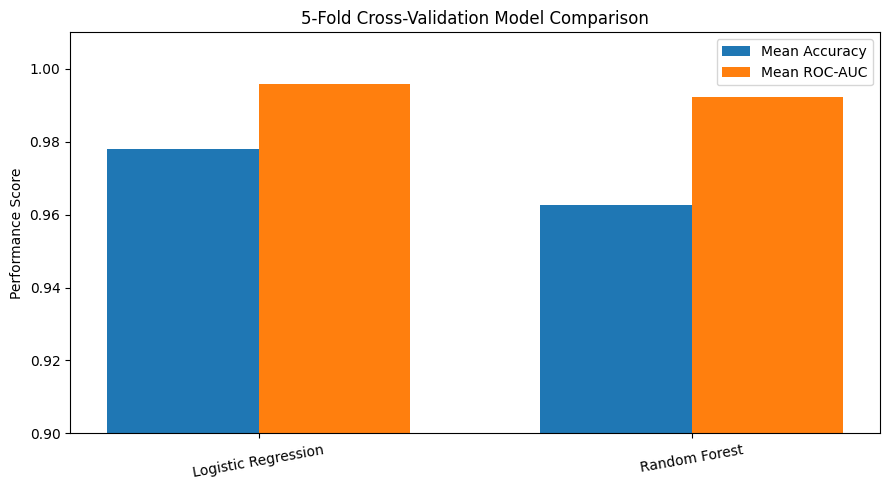

In [23]:
import matplotlib.pyplot as plt
import numpy as np

models = ["Logistic Regression", "Random Forest"]

accuracy_values = [
    lr_cv["test_accuracy"].mean(),
    rf_cv["test_accuracy"].mean()
]

auc_values = [
    lr_cv["test_roc_auc"].mean(),
    rf_cv["test_roc_auc"].mean()
]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width/2,
    accuracy_values,
    width,
    label="Mean Accuracy"
)

plt.bar(
    x + width/2,
    auc_values,
    width,
    label="Mean ROC-AUC"
)

plt.xticks(x, models, rotation=10)
plt.ylabel("Performance Score")
plt.ylim(0.90, 1.01)
plt.title("5-Fold Cross-Validation Model Comparison")
plt.legend()

plt.tight_layout()

plt.savefig(
    "OncoInsight_CrossValidation_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
!pip install shap -q

In [25]:
import shap

# Create an explainer for Logistic Regression
explainer = shap.Explainer(
    lr_model.predict,
    X_train
)

# Calculate SHAP values for test samples
shap_values = explainer(X_test)

print("SHAP analysis completed!")
print("SHAP values shape:", shap_values.values.shape)

SHAP analysis completed!
SHAP values shape: (114, 30)


/tmp/ipykernel_360/1500029988.py:1: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


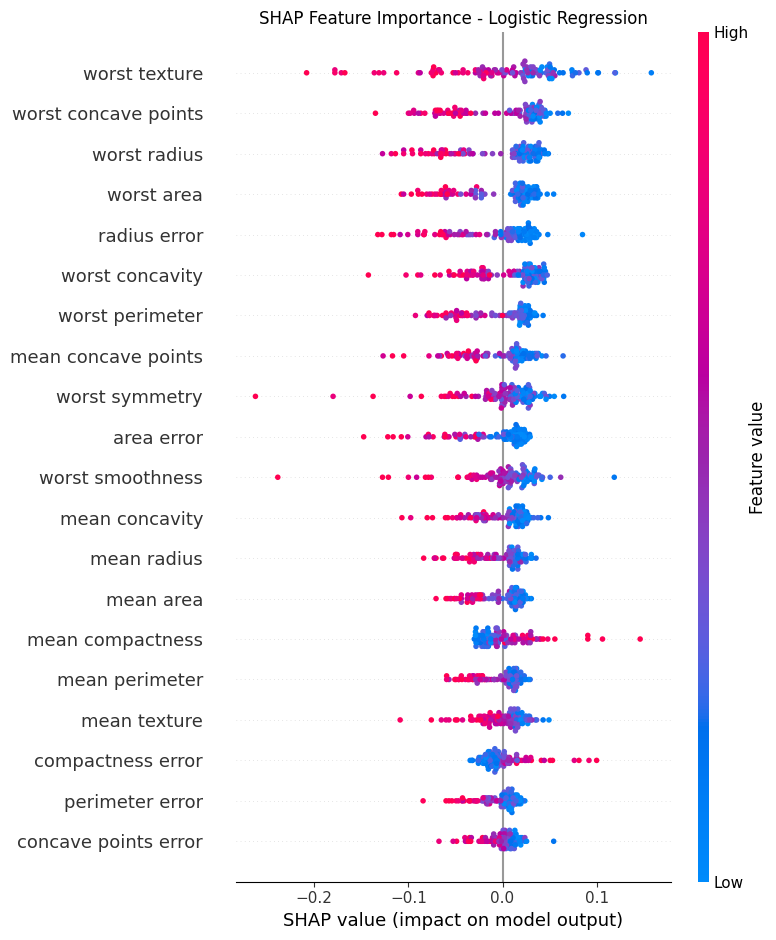

In [26]:
shap.summary_plot(
    shap_values,
    X_test,
    show=False
)

plt.title("SHAP Feature Importance - Logistic Regression")
plt.tight_layout()

plt.savefig(
    "OncoInsight_SHAP_Summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [27]:
# Explain probability of malignant classification (class 0)
malignant_explainer = shap.Explainer(
    lambda data: lr_model.predict_proba(data)[:, 0],
    X_train
)

malignant_shap_values = malignant_explainer(X_test)

print("Malignant probability SHAP analysis completed!")
print("SHAP values shape:", malignant_shap_values.values.shape)

Malignant probability SHAP analysis completed!
SHAP values shape: (114, 30)


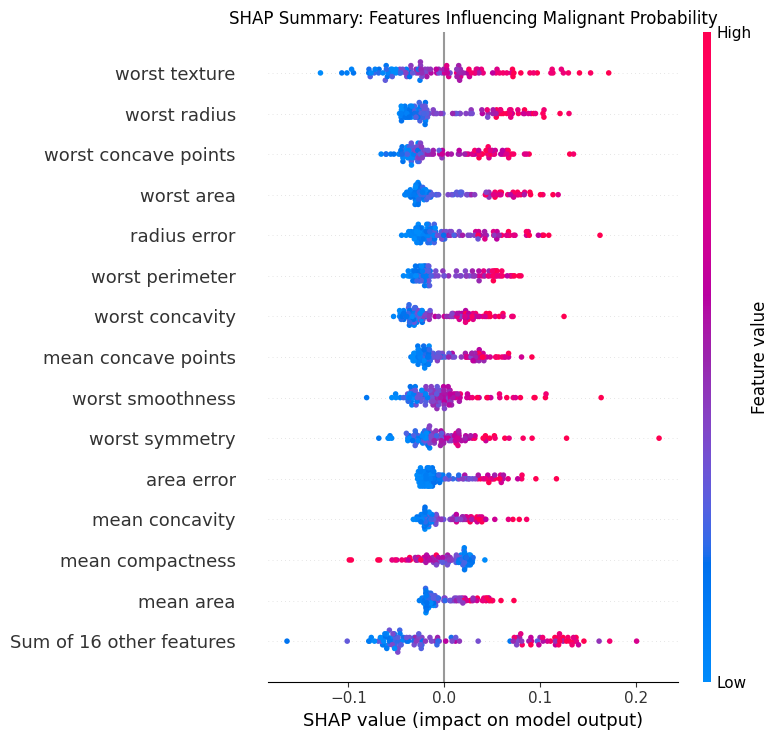

In [28]:
shap.plots.beeswarm(
    malignant_shap_values,
    max_display=15,
    show=False
)

plt.title("SHAP Summary: Features Influencing Malignant Probability")
plt.tight_layout()

plt.savefig(
    "OncoInsight_SHAP_Malignant_Probability.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_SHAP_Importance": np.abs(
        malignant_shap_values.values
    ).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    by="Mean_SHAP_Importance",
    ascending=False
)

print("TOP 15 SHAP FEATURES")
display(shap_importance.head(15).round(5))

TOP 15 SHAP FEATURES


,Feature,Mean_SHAP_Importance
21,worst texture,0.04839
20,worst radius,0.04157
27,worst concave points,0.03822
23,worst area,0.03647
10,radius error,0.03183
22,worst perimeter,0.03140
26,worst concavity,0.03064
7,mean concave points,0.02648
24,worst smoothness,0.02613
28,worst symmetry,0.02585


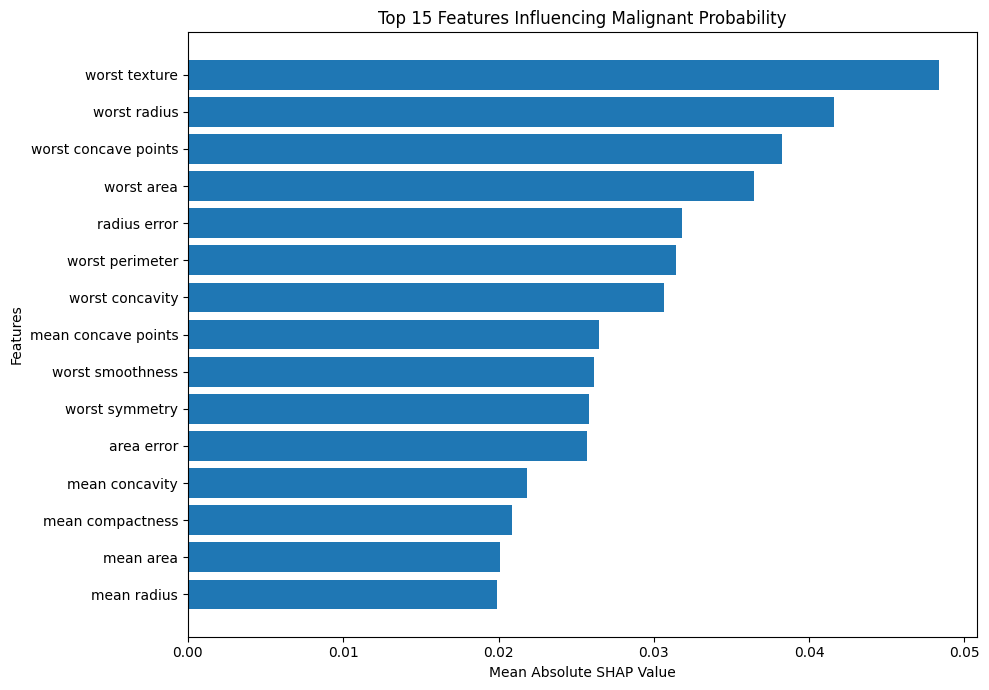

In [30]:
top_shap = shap_importance.head(15).sort_values(
    "Mean_SHAP_Importance"
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_shap["Feature"],
    top_shap["Mean_SHAP_Importance"]
)

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Top 15 Features Influencing Malignant Probability")

plt.tight_layout()

plt.savefig(
    "OncoInsight_SHAP_Feature_Importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [31]:
directional_shap = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_SHAP": malignant_shap_values.values.mean(axis=0),
    "Mean_Absolute_SHAP": np.abs(
        malignant_shap_values.values
    ).mean(axis=0)
})

directional_shap = directional_shap.sort_values(
    by="Mean_Absolute_SHAP",
    ascending=False
)

print("TOP 15 FEATURES AND THEIR SHAP DIRECTION")
display(directional_shap.head(15).round(5))

TOP 15 FEATURES AND THEIR SHAP DIRECTION


,Feature,Mean_SHAP,Mean_Absolute_SHAP
21,worst texture,-0.00051,0.04839
20,worst radius,0.00791,0.04157
27,worst concave points,0.00203,0.03822
23,worst area,0.00683,0.03647
10,radius error,0.00872,0.03183
22,worst perimeter,0.00490,0.03140
26,worst concavity,-0.00497,0.03064
7,mean concave points,0.00298,0.02648
24,worst smoothness,-0.00023,0.02613
28,worst symmetry,-0.00091,0.02585


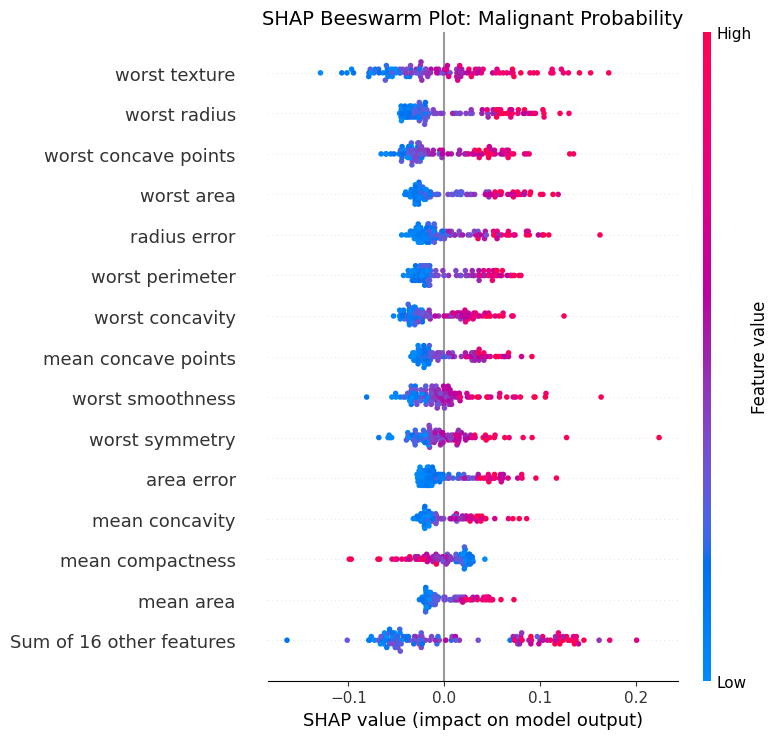

In [32]:
shap.plots.beeswarm(
    malignant_shap_values,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Beeswarm Plot: Malignant Probability",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    "OncoInsight_SHAP_Direction_Beeswarm.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
import os
import shutil

# Create project output folders
os.makedirs("OncoInsight-AI/results/figures", exist_ok=True)
os.makedirs("OncoInsight-AI/results/tables", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [34]:
# Save cross-validation results
cv_results.to_csv(
    "OncoInsight-AI/results/tables/model_cross_validation.csv",
    index=False
)

# Save model comparison
model_comparison.to_csv(
    "OncoInsight-AI/results/tables/model_comparison.csv",
    index=False
)

# Save Random Forest feature importance
feature_importance.to_csv(
    "OncoInsight-AI/results/tables/random_forest_feature_importance.csv",
    index=False
)

# Save SHAP feature importance
shap_importance.to_csv(
    "OncoInsight-AI/results/tables/shap_feature_importance.csv",
    index=False
)

# Save directional SHAP results
directional_shap.to_csv(
    "OncoInsight-AI/results/tables/shap_directional_analysis.csv",
    index=False
)

print("All result tables saved successfully!")

All result tables saved successfully!


In [35]:
figure_files = [
    "figures_diagnosis_distribution.png",
    "correlation_heatmap.png",
    "OncoInsight_Top15_Feature_Importance_Publication.png",
    "OncoInsight_CrossValidation_Comparison.png",
    "OncoInsight_SHAP_Summary.png",
    "OncoInsight_SHAP_Malignant_Probability.png",
    "OncoInsight_SHAP_Feature_Importance.png",
    "OncoInsight_SHAP_Direction_Beeswarm.png"
]

for file in figure_files:
    if os.path.exists(file):
        shutil.copy(
            file,
            "OncoInsight-AI/results/figures/"
        )
        print("Copied:", file)
    else:
        print("Not found:", file)

print("\nFigure organization completed!")

Copied: figures_diagnosis_distribution.png
Copied: correlation_heatmap.png
Copied: OncoInsight_Top15_Feature_Importance_Publication.png
Copied: OncoInsight_CrossValidation_Comparison.png
Copied: OncoInsight_SHAP_Summary.png
Copied: OncoInsight_SHAP_Malignant_Probability.png
Copied: OncoInsight_SHAP_Feature_Importance.png
Copied: OncoInsight_SHAP_Direction_Beeswarm.png

Figure organization completed!


In [36]:
readme_content = """
# OncoInsight-AI
## Explainable Machine Learning for Breast Cancer Classification

### Project Overview
OncoInsight-AI is a bioinformatics and machine learning project
that applies supervised learning and explainable AI to classify
breast cancer samples as benign or malignant.

The project uses the Breast Cancer Wisconsin Diagnostic dataset
from Scikit-learn.

### Dataset
- Total samples: 569
- Features: 30 numerical features
- Benign samples: 357
- Malignant samples: 212
- Missing values: None

The features describe characteristics of cell nuclei obtained
from digitized fine needle aspirate images.

### Methodology
1. Data loading and preprocessing
2. Exploratory data analysis
3. Correlation analysis
4. Train-test splitting (80:20)
5. Logistic Regression classification
6. Random Forest classification
7. Five-fold stratified cross-validation
8. Feature importance analysis
9. SHAP explainability

### Model Performance

| Model | Test Accuracy | Test ROC-AUC |
|---|---:|---:|
| Logistic Regression | 98.25% | 0.9954 |
| Random Forest | 94.74% | 0.9937 |

### Cross-validation Results

| Model | Mean Accuracy | Mean ROC-AUC |
|---|---:|---:|
| Logistic Regression | 97.80% | 0.9959 |
| Random Forest | 96.26% | 0.9923 |

### Important Predictive Features
- Worst perimeter
- Worst area
- Worst concave points
- Mean concave points
- Worst radius
- Worst texture

### Explainable AI
SHAP was used to investigate feature contributions to
malignant probability predictions.

### Biological Interpretation
Nuclear size, shape, concavity and texture measurements
contributed to the classification of benign and malignant
samples in this dataset.

These are morphological predictive features, not gene-expression
biomarkers.

### Repository Structure
- results/figures/: Analysis figures and visualizations
- results/tables/: Model performance and feature importance tables

### Tools and Technologies
- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- SHAP

### Limitations
This project uses a single train-test split and five-fold
cross-validation on the training data. Results are dataset-specific
and do not establish clinical diagnostic performance.

### Future Scope
- External validation using an independent dataset
- Integration of public breast cancer gene-expression data
- Molecular biomarker discovery
- Further explainability and model validation

### Disclaimer
This is an educational and research portfolio project.
It is not intended for clinical diagnosis or medical decision-making.
"""

with open("OncoInsight-AI/README.md", "w") as f:
    f.write(readme_content)

print("README.md created successfully!")

README.md created successfully!


In [37]:
for root, dirs, files in os.walk("OncoInsight-AI"):
    level = root.replace("OncoInsight-AI", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

OncoInsight-AI/
    README.md
    results/
        tables/
            shap_directional_analysis.csv
            random_forest_feature_importance.csv
            shap_feature_importance.csv
            model_comparison.csv
            model_cross_validation.csv
        figures/
            correlation_heatmap.png
            OncoInsight_SHAP_Direction_Beeswarm.png
            OncoInsight_SHAP_Summary.png
            figures_diagnosis_distribution.png
            OncoInsight_CrossValidation_Comparison.png
            OncoInsight_SHAP_Malignant_Probability.png
            OncoInsight_Top15_Feature_Importance_Publication.png
            OncoInsight_SHAP_Feature_Importance.png


In [38]:
import shutil
import os

zip_path = shutil.make_archive(
    "/content/OncoInsight-AI",
    "zip",
    root_dir="/content",
    base_dir="OncoInsight-AI"
)

print("ZIP backup created successfully!")
print("Location:", zip_path)
print("File size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

ZIP backup created successfully!
Location: /content/OncoInsight-AI.zip
File size (MB): 2.22


In [39]:
from google.colab import files

files.download("/content/OncoInsight-AI.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>